# Практическое занятие № 8 — конвейер Pipeline / ColumnTransformer
Цель: перенести преобразования занятия № 7 в единый воспроизводимый объект. **Никакого `fit` на val/test.**

**Входные данные:** в CSV отсутствует `courier_load`; этот столбец исключён, значения не выдумываются. Разбиение и эталонные результаты взяты из работы 7 с идентичным CSV. `vehicle_type` не добавляется в X. Новый числовой признак `is_weekend` построен из времени оформления; его полезность здесь не утверждается и по test не подбирается.

In [1]:
# Общая подготовка: одинаковая для практик 7 и 8
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

from IPython.display import display
import hashlib
PATH = Path('orders_dirty.csv')
if not PATH.exists():
    raise FileNotFoundError('Загрузите orders_dirty.csv в файлы Colab или измените PATH.')

source_hash = hashlib.sha256(PATH.read_bytes()).hexdigest()
df_raw = pd.read_csv(PATH, encoding='utf-8-sig')
expected = {'order_id','created_at','distance_km','zone','queue_size',
            'weather','promised_minutes','actual_minutes','late'}
missing_cols = expected - set(df_raw.columns)
assert not missing_cols, f'Отсутствуют необходимые поля: {sorted(missing_cols)}'
print('Сырой набор:', df_raw.shape, '; полные дубликаты:', int(df_raw.duplicated().sum()))

# Удаление полных повторов: не обучаем статистику и не используем test.
df = df_raw.drop_duplicates().copy()
df['late'] = pd.to_numeric(df['late'], errors='coerce')
actual = pd.to_numeric(df['actual_minutes'], errors='coerce')
promised = pd.to_numeric(df['promised_minutes'], errors='coerce')
valid_rule = actual.notna() & promised.notna() & df['late'].isin([0, 1])
conflict = valid_rule & (df['late'] != ((actual - promised) > 15).astype(int))
print('Конфликтных меток (проверяемых):', int(conflict.sum()))
df = df.loc[~conflict & df['late'].isin([0, 1])].copy()
df['late'] = df['late'].astype(int)
# Неполные / конфликтные сведения об идентификаторе требуют отдельного решения.
assert df['order_id'].notna().all(), 'Обнаружены пустые ID заказов.'
assert not df['order_id'].duplicated().any(), 'Есть повторные ID: требуется анализ причины, не случайное удаление.'
print('Рабочая копия:', df.shape)

split_path = Path('split_ids_06.csv')  # Необязательный экспорт из практики № 6
if split_path.exists():
    splits = pd.read_csv(split_path, dtype={'order_id': str})
    assert {'order_id', 'split'} <= set(splits.columns)
    splits['split'] = splits['split'].replace({'validation': 'val'})
    assert set(splits['split']) <= {'train', 'val', 'test'}
    assert splits['order_id'].is_unique
    x = df.assign(order_id=df['order_id'].astype(str)).merge(
        splits[['order_id', 'split']], on='order_id', how='left', validate='one_to_one')
    assert x['split'].notna().all(), 'В split_ids_06.csv перечислены не все рабочие заказы.'
    assert set(splits['order_id']) == set(x['order_id'])
    train = x.loc[x['split'] == 'train'].drop(columns='split').copy()
    val   = x.loc[x['split'] == 'val'].drop(columns='split').copy()
    test  = x.loc[x['split'] == 'test'].drop(columns='split').copy()
else:
    # Воссоздание схемы практики № 6, если файл с IDs не был сохранён.
    train_dev, test = train_test_split(df, test_size=.20, stratify=df['late'], random_state=42)
    train, val = train_test_split(train_dev, test_size=.25,
                                 stratify=train_dev['late'], random_state=42)
    split_export = pd.concat([
       train[['order_id']].assign(split='train'),
       val[['order_id']].assign(split='val'),
       test[['order_id']].assign(split='test')], ignore_index=True)
    split_export.to_csv('split_ids_06.csv', index=False)

sets = [set(a['order_id']) for a in (train, val, test)]
assert len(sets[0]&sets[1]) == len(sets[0]&sets[2]) == len(sets[1]&sets[2]) == 0
assert sets[0]|sets[1]|sets[2] == set(df['order_id'])
assert len(train)+len(val)+len(test) == len(df)
print('train / val / test:', len(train), len(val), len(test))

split_summary = pd.DataFrame([{'subset': label, 'N': len(part),
    'late_0': int((part.late == 0).sum()), 'late_1': int(part.late.sum()),
    'late_pct': 100*part.late.mean()} for label, part in [('train', train), ('val', val), ('test', test)]])
display(split_summary)
split_summary.to_csv('08_split_summary.csv', index=False)

Сырой набор: (600, 10) ; полные дубликаты: 1
Конфликтных меток (проверяемых): 1
Рабочая копия: (598, 10)
train / val / test: 358 120 120


,subset,N,late_0,late_1,late_pct
0,train,358,190,168,46.927374
1,val,120,64,56,46.666667
2,test,120,64,56,46.666667


## Этап 1. Детерминированное выделение признаков внутри конвейера

In [2]:
# В Colab функция экспортируется в обычный модуль для безопасного joblib.dump.
# При перезапуске блокнота модуль восстанавливается автоматически.
from pathlib import Path
Path('tyumgu_feature_rules.py').write_text("# Правила преобразования признаков для занятий 7–8\nimport numpy as np\nimport pandas as pd\nNUM_BASE = ['distance_km', 'queue_size',  'promised_minutes']\nCAT = ['zone', 'weather']\nNUM = NUM_BASE + ['hour_sin', 'hour_cos', 'planned_speed_kmh', 'is_weekend']\nINPUT = NUM_BASE + CAT + ['created_at']\n\ndef make_features(X):\n    f = X.loc[:, INPUT].copy()\n    for name in NUM_BASE:\n        f[name] = pd.to_numeric(f[name], errors='coerce')\n    for name in NUM_BASE:\n        f.loc[f[name] < 0, name] = np.nan\n    f.loc[f['promised_minutes'] == 0, 'promised_minutes'] = np.nan\n    for name in CAT:\n        s = f[name].astype('string').str.strip()\n        s = s.mask(s.str.lower().isin(['', 'nan', 'none', 'нет данных', 'неизвестно', 'null']))\n        f[name] = s.astype(object).where(s.notna(), np.nan)\n    time = pd.to_datetime(f['created_at'], errors='coerce')\n    hour = time.dt.hour.astype(float)\n    f['is_weekend'] = (time.dt.dayofweek >= 5).astype(float).where(time.notna(), np.nan)\n    f['hour_sin'] = np.sin(2*np.pi*hour/24)\n    f['hour_cos'] = np.cos(2*np.pi*hour/24)\n    f['planned_speed_kmh'] = 60*f['distance_km']/f['promised_minutes']\n    f['planned_speed_kmh'] = f['planned_speed_kmh'].replace([np.inf, -np.inf], np.nan)\n    return f.drop(columns='created_at')\n", encoding='utf-8')
import importlib
import tyumgu_feature_rules
importlib.reload(tyumgu_feature_rules)
from tyumgu_feature_rules import NUM_BASE, NUM, CAT, INPUT, make_features
F_train, F_val, F_test = [make_features(part) for part in (train,val,test)]
assert set(F_train.columns) == set(NUM + CAT)
assert all(col not in F_train.columns for col in ('late','actual_minutes','order_id'))
print('Матрица до кодирования:', F_train.shape)
print('Числовые столбцы:', NUM, '; категориальные:', CAT)

print('is_weekend = 1 для субботы/воскресенья, 0 для будней; невалидная дата даёт NaN.')
print('Гипотеза: выходные могут менять нагрузку доставки. Признак выбран до оценки метрик.')
display(F_train[['hour_sin', 'hour_cos', 'planned_speed_kmh', 'is_weekend']].head())

Матрица до кодирования: (358, 9)
Числовые столбцы: ['distance_km', 'queue_size', 'promised_minutes', 'hour_sin', 'hour_cos', 'planned_speed_kmh', 'is_weekend'] ; категориальные: ['zone', 'weather']
is_weekend = 1 для субботы/воскресенья, 0 для будней; невалидная дата даёт NaN.
Гипотеза: выходные могут менять нагрузку доставки. Признак выбран до оценки метрик.


,hour_sin,hour_cos,planned_speed_kmh,is_weekend
0,0.866025,-0.500000,9.152542,0.0
1,-0.965926,-0.258819,9.771429,0.0
4,-0.866025,0.500000,9.321429,0.0
5,0.965926,0.258819,12.290323,0.0
6,-0.500000,-0.866025,7.363636,0.0


## Этап 2. ColumnTransformer + Pipeline

In [3]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

numeric_pipe = Pipeline([
    ('fill', SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)),
    ('scale', StandardScaler())
])
cat_pipe = Pipeline([
    ('fill', SimpleImputer(strategy='constant', fill_value='неизвестно')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocess = ColumnTransformer([
    ('num', numeric_pipe, NUM),
    ('cat', cat_pipe, CAT)
], remainder='drop', verbose_feature_names_out=True)
# make_features возвращает pandas DataFrame, названия столбцов остаются доступными.
feature_pipeline = Pipeline([
    ('derive', FunctionTransformer(make_features, validate=False)),
    ('prep', preprocess)
])
BASE_X = INPUT
Xtrain = train[BASE_X]; Xval = val[BASE_X]; Xtest = test[BASE_X]
Xt_train = feature_pipeline.fit_transform(Xtrain)
Xt_val = feature_pipeline.transform(Xval)
Xt_test = feature_pipeline.transform(Xtest)
fnames = feature_pipeline.named_steps['prep'].get_feature_names_out()
assert Xt_train.shape[1] == Xt_val.shape[1] == Xt_test.shape[1] == len(fnames)
assert np.isfinite(Xt_train).all() and np.isfinite(Xt_val).all() and np.isfinite(Xt_test).all()
print('Размеры:', Xt_train.shape, Xt_val.shape, Xt_test.shape)
print('Список итоговых признаков:', list(fnames))

# Сохраняем и предъявляем входы, отдельно от меток и ID.
dimensions = []
for label, X, Xt, part in [('train', Xtrain, Xt_train, train), ('val', Xval, Xt_val, val), ('test', Xtest, Xt_test, test)]:
    print(label, 'до обработки:')
    display(X.head())
    assert Xt.shape[0] == len(X) == len(part)
    assert len(set(fnames)) == len(fnames)
    assert {'late', 'actual_minutes', 'order_id'}.isdisjoint(X.columns)
    X.to_csv(f'08_input_{label}.csv', index=False)
    pd.DataFrame(Xt, columns=fnames).to_csv(f'08_X_{label}.csv', index=False)
    part[['order_id', 'late']].to_csv(f'08_y_{label}.csv', index=False)
    dimensions.append({'subset': label, 'rows_before': len(X), 'rows_after': len(Xt),
                       'columns_before': X.shape[1], 'columns_after': Xt.shape[1]})
dimensions = pd.DataFrame(dimensions)
display(dimensions)
dimensions.to_csv('08_dimensions.csv', index=False)

Размеры: (358, 17) (120, 17) (120, 17)
Список итоговых признаков: ['num__distance_km', 'num__queue_size', 'num__promised_minutes', 'num__hour_sin', 'num__hour_cos', 'num__planned_speed_kmh', 'num__is_weekend', 'num__missingindicator_distance_km', 'num__missingindicator_queue_size', 'num__missingindicator_planned_speed_kmh', 'cat__zone_center', 'cat__zone_east', 'cat__zone_north', 'cat__zone_south', 'cat__weather_clear', 'cat__weather_rain', 'cat__weather_snow']
train до обработки:


,distance_km,queue_size,promised_minutes,zone,weather,created_at
0,9.0,11.0,59,north,snow,2026-08-25 08:00:00
1,5.7,0.0,35,south,rain,2026-08-25 17:17:00
4,8.7,12.0,56,center,clear,2026-08-26 20:13:00
5,12.7,5.0,62,south,clear,2026-08-27 05:30:00
6,5.4,9.0,44,north,clear,2026-08-27 14:47:00


val до обработки:


,distance_km,queue_size,promised_minutes,zone,weather,created_at
3,12.4,0.0,55,south,rain,2026-08-26 11:51:00
9,"12,5",9.0,59,south,rain,2026-08-28 17:43:00
10,13.6,4.0,61,south,clear,2026-08-29 02:05:00
11,14.4,9.0,72,south,clear,2026-08-29 11:22:00
12,4.4,11.0,41,center,clear,2026-08-29 20:39:00


test до обработки:


,distance_km,queue_size,promised_minutes,zone,weather,created_at
2,8.5,1.0,48,south,clear,2026-08-26 02:34:00
18,9.3,12.0,57,center,clear,2026-09-01 02:31:00
26,13.3,2.0,57,east,clear,2026-09-04 02:02:00
28,6.0,8.0,43,south,snow,2026-09-04 20:36:00
37,6.3,11.0,46,center,clear,2026-09-08 14:41:00


,subset,rows_before,rows_after,columns_before,columns_after
0,train,358,358,6,17
1,val,120,120,6,17
2,test,120,120,6,17


## Этап 3. Проверка отсутствия утечки и стабильности схемы

In [4]:
assert {'order_id','late','actual_minutes'}.isdisjoint(Xtrain.columns)
assert {'order_id','late','actual_minutes'}.isdisjoint(F_train.columns)
# Параметры взяты из train (демонстрация первой числовой медианы).
learned = feature_pipeline.named_steps['prep'].named_transformers_['num'].named_steps['fill'].statistics_
print('Медианы train:', dict(zip(NUM, learned[:len(NUM)])))
# Проверяем незнакомую категорию в одном примере.
new_order = Xval.iloc[[0]].copy() if len(Xval) else Xtrain.iloc[[0]].copy()
new_order.loc[:, 'zone'] = '__НОВАЯ_ЗОНА__'
assert feature_pipeline.transform(new_order).shape[1] == Xt_train.shape[1]
# Test лишь преобразован по статистике train; model selection по test запрещён.
print('Проверка новой категории пройдена.')

# Проверяем все медианы, масштабы и словари непосредственно по train.
num_fitted = feature_pipeline.named_steps['prep'].named_transformers_['num']
cat_fitted = feature_pipeline.named_steps['prep'].named_transformers_['cat']
fill = num_fitted.named_steps['fill']
scale = num_fitted.named_steps['scale']
encoder = cat_fitted.named_steps['onehot']
np.testing.assert_allclose(learned, F_train[NUM].median().to_numpy())
imputed_train = fill.transform(F_train[NUM])
np.testing.assert_allclose(scale.mean_, imputed_train.mean(axis=0))
np.testing.assert_allclose(scale.var_, imputed_train.var(axis=0))
train_categories = cat_fitted.named_steps['fill'].transform(F_train[CAT])
for i, values in enumerate(encoder.categories_):
    np.testing.assert_array_equal(values, np.unique(train_categories[:, i]))
parameters = pd.DataFrame({'feature': fill.get_feature_names_out(NUM),
    'median': list(learned) + [np.nan]*(len(scale.mean_) - len(NUM)),
    'scaler_mean': scale.mean_, 'scaler_scale': scale.scale_})
display(parameters)
parameters.to_csv('08_transform_parameters.csv', index=False)
categories = pd.DataFrame([{'feature': col, 'category': value}
    for col, values in zip(CAT, encoder.categories_) for value in values])
display(categories)
categories.to_csv('08_categories.csv', index=False)

# Неизменность всех обученных параметров при transform val/test и новых данных.
import joblib
before = joblib.hash(feature_pipeline)
for X in (Xval, Xtest, new_order):
    feature_pipeline.transform(X)
assert before == joblib.hash(feature_pipeline)
new_values = feature_pipeline.transform(new_order)
zone_cols = np.array([name.startswith('cat__zone_') for name in fnames])
assert '__НОВАЯ_ЗОНА__' not in encoder.categories_[0]
assert np.count_nonzero(new_values[:, zone_cols]) == 0
np.testing.assert_array_equal(new_values[:, ~zone_cols], Xt_val[:1, ~zone_cols])
display(pd.DataFrame(new_values, columns=fnames))
strict = OneHotEncoder(handle_unknown='error', sparse_output=False).fit(train_categories)
new_cat = cat_fitted.named_steps['fill'].transform(make_features(new_order)[CAT])
try:
    strict.transform(new_cat)
except ValueError as exc:
    print('Ожидаемый ValueError при handle_unknown="error":', exc)
else:
    raise AssertionError('Новая категория должна вызвать ValueError')

# Сравнение с ручными матрицами № 7: выравниваем строки по ID и столбцы по именам.
# Базовый конвейер без нового признака нужен для полного равенства схемы.
BASE_NUM = [name for name in NUM if name != 'is_weekend']
baseline = clone(feature_pipeline)
baseline.set_params(prep__transformers=[('num', clone(numeric_pipe), BASE_NUM),
                                      ('cat', clone(cat_pipe), CAT)])
baseline.fit(Xtrain)
base_names = baseline.named_steps['prep'].get_feature_names_out()
strip_prefix = lambda names: [name.split('__', 1)[1] for name in names]
comparisons = []
for label, X, Xt, part in [('train', Xtrain, Xt_train, train), ('val', Xval, Xt_val, val), ('test', Xtest, Xt_test, test)]:
    manual = pd.read_csv(f'reference_lb7/07_X_{label}.csv')
    manual_y = pd.read_csv(f'reference_lb7/07_y_{label}.csv')
    assert manual_y.order_id.is_unique and set(manual_y.order_id) == set(part.order_id)
    manual.index = manual_y.order_id
    manual = manual.loc[part.order_id]
    np.testing.assert_array_equal(manual_y.set_index('order_id').loc[part.order_id, 'late'], part.late)
    basic = pd.DataFrame(baseline.transform(X), columns=strip_prefix(base_names), index=part.order_id)
    assert set(basic.columns) == set(manual.columns)
    basic = basic[manual.columns]
    extended = pd.DataFrame(Xt, columns=strip_prefix(fnames), index=part.order_id)[manual.columns]
    np.testing.assert_allclose(manual, basic, atol=1e-12, rtol=1e-12)
    np.testing.assert_allclose(manual, extended, atol=1e-12, rtol=1e-12)
    comparisons.append({'subset': label, 'rows': len(X), 'manual_columns': manual.shape[1],
        'baseline_columns': basic.shape[1], 'extended_columns': Xt.shape[1],
        'max_abs_diff': float(np.max(np.abs(manual.to_numpy()-basic.to_numpy()))),
        'extended_common_max_abs_diff': float(np.max(np.abs(manual.to_numpy()-extended.to_numpy())))})
comparison = pd.DataFrame(comparisons)
display(comparison)
comparison.to_csv('08_manual_comparison.csv', index=False)
previous_params = pd.read_csv('reference_lb7/07_transform_parameters.csv').set_index('feature')
current_params = parameters.set_index('feature').loc[previous_params.index]
np.testing.assert_allclose(current_params.scaler_mean, previous_params.scaler_mean, atol=1e-12)
np.testing.assert_allclose(current_params.scaler_scale, previous_params.scaler_scale, atol=1e-12)
np.testing.assert_allclose(current_params['median'], previous_params.imputer_median, equal_nan=True, atol=1e-12)
print('Медианы, средние и масштабы общих признаков совпали с работой 7.')

# Дополнительные проверки фиксированных правил без переобучения.
edge_checks = []
fixed_hash = joblib.hash(feature_pipeline)
weather_probe = Xval.iloc[[0]].copy()
weather_probe.loc[:, 'weather'] = '__НОВАЯ_ПОГОДА__'
weather_values = feature_pipeline.transform(weather_probe)
weather_cols = np.array([name.startswith('cat__weather_') for name in fnames])
assert np.count_nonzero(weather_values[:, weather_cols]) == 0
np.testing.assert_array_equal(weather_values[:, ~weather_cols], Xt_val[:1, ~weather_cols])
edge_checks.append({'check': 'unknown_weather_zero_block', 'passed': True})

zero_probe = Xval.iloc[[0]].copy()
zero_probe['promised_minutes'] = 0
zero_features = make_features(zero_probe)
assert zero_features[['promised_minutes', 'planned_speed_kmh']].isna().all().all()
assert np.isfinite(feature_pipeline.transform(zero_probe)).all()
edge_checks.append({'check': 'zero_promised_imputed_without_infinity', 'passed': True})

date_probe = Xval.iloc[[0]].copy()
date_probe['created_at'] = 'invalid-date'
assert make_features(date_probe)[['hour_sin', 'hour_cos', 'is_weekend']].isna().all().all()
assert np.isfinite(feature_pipeline.transform(date_probe)).all()
edge_checks.append({'check': 'invalid_date_imputed', 'passed': True})

calendar_probe = pd.concat([Xval.iloc[[0]]]*3, ignore_index=True)
calendar_probe['created_at'] = ['2026-10-23 12:00:00', '2026-10-24 12:00:00', '2026-10-25 12:00:00']
np.testing.assert_array_equal(make_features(calendar_probe).is_weekend, [0., 1., 1.])
edge_checks.append({'check': 'friday_saturday_sunday_indicator', 'passed': True})
assert fixed_hash == joblib.hash(feature_pipeline)
edge_checks.append({'check': 'no_refit_in_edge_checks', 'passed': True})
edge_checks = pd.DataFrame(edge_checks)
display(edge_checks)
edge_checks.to_csv('08_edge_checks.csv', index=False)
print('Индикаторы пропуска создаются только для полей с пропусками в train; новые пропуски в других полях импутируются без нового столбца.')



Медианы train: {'distance_km': np.float64(8.5), 'queue_size': np.float64(10.0), 'promised_minutes': np.float64(49.5), 'hour_sin': np.float64(0.0), 'hour_cos': np.float64(-1.8369701987210297e-16), 'planned_speed_kmh': np.float64(10.0), 'is_weekend': np.float64(0.0)}
Проверка новой категории пройдена.


,feature,median,scaler_mean,scaler_scale
0,distance_km,8.500000e+00,8.828492,5.479217
1,queue_size,1.000000e+01,10.282123,6.239741
2,promised_minutes,4.950000e+01,50.030726,14.647121
3,hour_sin,0.000000e+00,-0.029507,0.709344
4,hour_cos,-1.836970e-16,-0.022551,0.703883
5,planned_speed_kmh,1.000000e+01,9.811495,4.980269
6,is_weekend,0.000000e+00,0.279330,0.448670
7,missingindicator_distance_km,NaN,0.002793,0.052778
8,missingindicator_queue_size,NaN,0.002793,0.052778
9,missingindicator_planned_speed_kmh,NaN,0.002793,0.052778


,feature,category
0,zone,center
1,zone,east
2,zone,north
3,zone,south
4,weather,clear
5,weather,rain
6,weather,snow


,num__distance_km,num__queue_size,num__promised_minutes,num__hour_sin,num__hour_cos,num__planned_speed_kmh,num__is_weekend,num__missingindicator_distance_km,num__missingindicator_queue_size,num__missingindicator_planned_speed_kmh,cat__zone_center,cat__zone_east,cat__zone_north,cat__zone_south,cat__weather_clear,cat__weather_rain,cat__weather_snow
0,0.651828,-1.647844,0.339266,0.406469,-1.340242,0.7461,-0.622573,-0.052926,-0.052926,-0.052926,0.0,0.0,0.0,0.0,0.0,1.0,0.0


Ожидаемый ValueError при handle_unknown="error": Found unknown categories ['__НОВАЯ_ЗОНА__'] in column 0 during transform


,subset,rows,manual_columns,baseline_columns,extended_columns,max_abs_diff,extended_common_max_abs_diff
0,train,358,16,16,17,0.0,0.0
1,val,120,16,16,17,0.0,0.0
2,test,120,16,16,17,0.0,0.0


Медианы, средние и масштабы общих признаков совпали с работой 7.


,check,passed
0,unknown_weather_zero_block,True
1,zero_promised_imputed_without_infinity,True
2,invalid_date_imputed,True
3,friday_saturday_sunday_indicator,True
4,no_refit_in_edge_checks,True


Индикаторы пропуска создаются только для полей с пропусками в train; новые пропуски в других полях импутируются без нового столбца.


## Этап 4. Минимальная модель только для контроля сквозного конвейера
На занятиях № 9–10 изучается полноценное сравнение моделей. Здесь логистическая регрессия — проверка, что шаги работают вместе.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, balanced_accuracy_score, roc_auc_score
model = Pipeline([
    ('derive', FunctionTransformer(make_features, validate=False)),
    ('prep', clone(preprocess)),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])
assert train['late'].nunique() == 2, 'Для логистической регрессии в train нужны оба класса.'
model.fit(Xtrain, train['late'])
yp = model.predict(Xval)
proba = model.predict_proba(Xval)[:,1]
print('Validation balanced accuracy:', round(balanced_accuracy_score(val['late'],yp),3))
print('Validation F1:', round(f1_score(val['late'],yp,zero_division=0),3))
if val['late'].nunique() == 2:
    print('Validation ROC-AUC:', round(roc_auc_score(val['late'],proba),3))
# Здесь специально не считаем test-score: тест откладываем до финальной оценки.

metrics = pd.DataFrame([{'subset': 'val', 'N': len(val),
    'late_pct': 100*val.late.mean(), 'balanced_accuracy': balanced_accuracy_score(val.late, yp),
    'f1': f1_score(val.late, yp, zero_division=0),
    'roc_auc': roc_auc_score(val.late, proba) if val.late.nunique() == 2 else np.nan}])
display(metrics)
metrics.to_csv('08_validation_metrics.csv', index=False)
pd.DataFrame({'order_id': val.order_id, 'late': val.late, 'prediction': yp,
              'probability': proba}).to_csv('08_validation_predictions.csv', index=False)
from sklearn.metrics import confusion_matrix
display(pd.DataFrame(confusion_matrix(val.late, yp),
                     index=['actual_0', 'actual_1'], columns=['predicted_0', 'predicted_1']))
print('Одна заранее заданная модель и порог 0.5. Это диагностика, не доказательство качества на реальных данных.')

# Диагностическая модель должна использовать ту же подготовку, что и отдельный Pipeline.
np.testing.assert_allclose(model[:-1].transform(Xval), Xt_val, atol=1e-12, rtol=1e-12)
assert model.named_steps['clf'].n_iter_.max() < model.named_steps['clf'].max_iter



Validation balanced accuracy: 0.69
Validation F1: 0.667
Validation ROC-AUC: 0.755


,subset,N,late_pct,balanced_accuracy,f1,roc_auc
0,val,120,46.666667,0.689732,0.666667,0.754743


,predicted_0,predicted_1
actual_0,46,18
actual_1,19,37


Одна заранее заданная модель и порог 0.5. Это диагностика, не доказательство качества на реальных данных.


## Этап 5. Сохранение, повторный запуск, документирование

Контроль повторной загрузки успешен. Файлы joblib загружайте только из доверенных источников.
{"fresh_process": true, "rows": 120, "columns": 17, "max_abs_diff": 0.0, "predictions_equal": true, "schema_equal": true, "row_ids_equal": true, "metrics_recomputed": true, "model_preprocessing_equal": true}



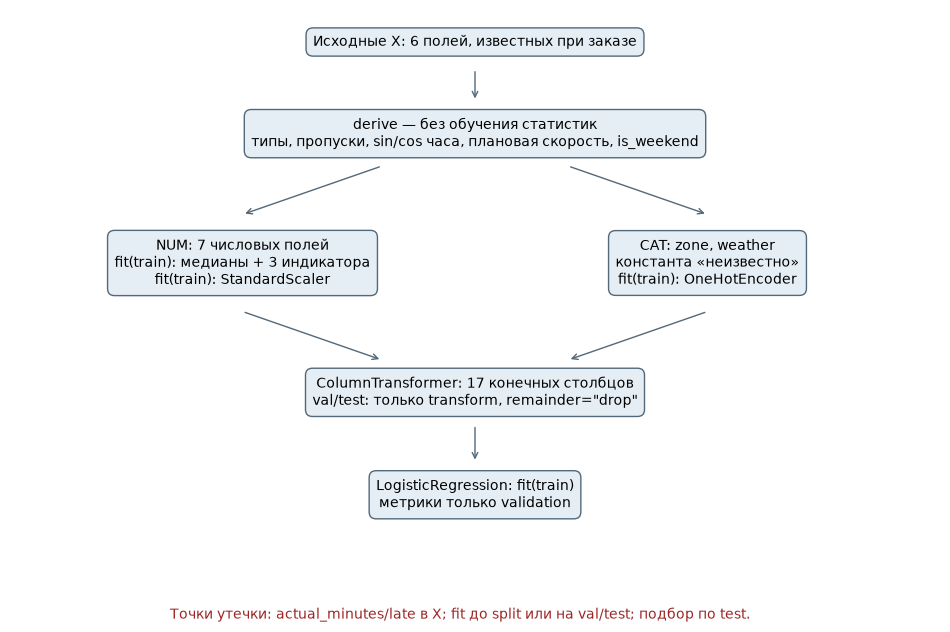

In [6]:
import joblib
joblib.dump(feature_pipeline,'08_feature_pipeline.joblib')
joblib.dump(model,'08_demo_model.joblib')
pd.DataFrame({'feature_name':fnames}).to_csv('08_feature_schema.csv',index=False)
reloaded = joblib.load('08_feature_pipeline.joblib')
assert np.allclose(reloaded.transform(Xval),Xt_val,atol=1e-9)
print('Контроль повторной загрузки успешен. Файлы joblib загружайте только из доверенных источников.')

reloaded_model = joblib.load('08_demo_model.joblib')
np.testing.assert_allclose(reloaded_model.predict_proba(Xval)[:, 1], proba, atol=1e-12)
# Проверка в новом процессе: функции не берутся из состояния текущего ядра.
import subprocess
import sys
np.save('08_validation_reference.npy', Xt_val)
fresh = subprocess.run([sys.executable, 'verify_saved.py'], check=True, capture_output=True, text=True)
print(fresh.stdout)
assert hashlib.sha256(PATH.read_bytes()).hexdigest() == source_hash

# Полная схема с обучаемыми узлами и потенциальными точками утечки.
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12, 7))
ax.set(xlim=(0, 1), ylim=(0, 1)); ax.axis('off')
def box(x, y, text, color='#E6EEF5'):
    ax.text(x, y, text, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=0.5', facecolor=color, edgecolor='#536879'))
def arrow(a, b): ax.annotate('', xy=b, xytext=a, arrowprops=dict(arrowstyle='->', color='#536879'))
box(.5,.94,'Исходные X: 6 полей, известных при заказе')
box(.5,.77,'derive — без обучения статистик\nтипы, пропуски, sin/cos часа, плановая скорость, is_weekend')
box(.25,.53,'NUM: 7 числовых полей\nfit(train): медианы + 3 индикатора\nfit(train): StandardScaler')
box(.75,.53,'CAT: zone, weather\nконстанта «неизвестно»\nfit(train): OneHotEncoder')
box(.5,.29,'ColumnTransformer: 17 конечных столбцов\nval/test: только transform, remainder="drop"')
box(.5,.10,'LogisticRegression: fit(train)\nметрики только validation')
for a,b in [((.5,.89),(.5,.83)),((.4,.71),(.25,.62)),((.6,.71),(.75,.62)),
            ((.25,.44),(.4,.35)),((.75,.44),(.6,.35)),((.5,.23),(.5,.16))]: arrow(a,b)
fig.text(.5,.01,'Точки утечки: actual_minutes/late в X; fit до split или на val/test; подбор по test.',
         ha='center', color='#9C2525', fontsize=10)
plt.savefig('08_pipeline_diagram.png', dpi=160, bbox_inches='tight'); plt.show()

## Самостоятельная проверка
1. Объясните `fit`, `transform`, `fit_transform` на примере median/StandardScaler/OneHot.
2. Почему `ColumnTransformer` полезнее ручного склеивания?
3. Добавьте к `NUM` новый обоснованный числовой признак. Проверьте стабильность схемы.
4. Нарисуйте схему конвейера и отметьте точки утечки.
5. Что будет, если новую категорию подать в `OneHotEncoder(handle_unknown="error")`?
6. Сравните ручную матрицу занятия № 7 с результатом `feature_pipeline`.

**Результат:** отчёт, исполняемый блокнот, сохраняемый конвейер и таблица признаков.

### Выполненные самостоятельные задания

1. `fit` оценивает параметры: медианы imputer, средние и дисперсии scaler, словари One-Hot. `transform` использует их без изменения; `fit_transform` совмещает обе операции и применяется только к train. Детерминированная функция derive не оценивает статистик.
2. ColumnTransformer закрепляет имена и порядок групп колонок, обучает каждую ветвь в одном объекте и воспроизводимо объединяет результат. Ручная склейка требует отдельно контролировать порядок и перенос параметров.
3. В NUM добавлен `is_weekend`: суббота/воскресенье = 1, будни = 0; невалидная дата = NaN. Он известен при создании и может отражать режим нагрузки. Схема стабильна на всех выборках: 6 входов → 17 выходов. Его полезность не проверяется по test.
4. Схема сохранена в `08_pipeline_diagram.png`. Обучаемые узлы обозначены fit(train); источники утечек подписаны снизу.
5. Вариант `handle_unknown="error"`, обученный на train, действительно вызвал ожидаемый ValueError для новой зоны. Основной вариант ignore выдал нули в блоке zone, сохранив остальные признаки и число колонок.
6. Эталонные матрицы работы 7 сопоставлены по order_id, колонки — по именам без префиксов num__/cat__. Базовый Pipeline без is_weekend совпал по всем 16 столбцам; расширенный совпал по всем общим столбцам. Отдельно сверены медианы, средние и масштабы. Допуск 10⁻¹² учитывает сохранение чисел в CSV.

### Контрольные вопросы

- Различия fit/transform/fit_transform приведены выше. Повторный fit на val/test меняет параметры и вызывает утечку.
- StandardScaler сохраняет mean_, var_, scale_ и число увиденных объектов; OneHotEncoder — categories_ и правила обработки неизвестных значений.
- FunctionTransformer идёт первым, поскольку ColumnTransformer ожидает числовые типы и уже созданные производные колонки.
- remainder="drop" исключает невыбранные колонки на этапе объединения ветвей. Это не защита от ошибочного включения actual_minutes в NUM и не отменяет проверки доступных X на входе.
- При новой weather основной One-Hot выдаст нулевой блок weather; зона и остальные признаки сохранятся. При режиме error возникнет ValueError. Пропущенная погода заменяется константой, которая тоже будет неизвестной, если не встретилась в train.
- По test нельзя выбирать модель, C/регуляризацию, порог классификации, набор признаков, импутацию или масштабирование. Здесь эти решения зафиксированы заранее, метрики считаются только на val.
- Сохранённый конвейер содержит шаги, их настройки и обученные статистики; модель дополнительно хранит коэффициенты классификатора. Таблица Xt_train хранит лишь готовые числа и не умеет преобразовывать новые заказы. Для загрузки нужны совместимые версии библиотек и модуль tyumgu_feature_rules.py: функция хранится как ссылка на модуль, а не как автономный текст. joblib загружается только из доверенного источника.

### Вывод

Обработка сведена к воспроизводимому Pipeline с двумя ветвями ColumnTransformer. Статистики всех обучаемых шагов получены исключительно из train. Общие признаки совпали с ручной обработкой работы 7 после выравнивания строк и колонок. Добавленный календарный признак сохранил одинаковую размерность всех выборок. Новая категория не нарушила схему, хотя сведения о её специфике потеряны. Диагностическая модель оценена только на validation и не служит доказательством качества на реальных данных. Конвейер и модель повторно загружены в новом процессе, а исходный CSV остался неизменным.

**Дополнительная проверка.** Новая погода даёт нулевой блок weather; нулевая обещанная длительность не приводит к бесконечностям; невалидная дата импутируется; is_weekend проверен на пятнице, субботе и воскресенье. Во всех случаях параметры остаются неизменными. add_indicator создаёт индикаторы только для признаков, где пропуски были на train: возникшие позднее пропуски в остальных полях заполняются без расширения схемы. При загрузке отдельно сверены имена признаков, порядок ID, подготовка внутри модели и метрики, пересчитанные по сохранённым validation-предсказаниям.
